*© Sabrine Bendimerad · [sbendimerad.github.io](https://sbendimerad.github.io) · Licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/): you may share and adapt this material with credit, for non-commercial use, under the same licence. Datasets keep their own licences.*

# Challenge: predict conversions, template 🏆

This template implements every step of the challenge for a **very simple baseline**: a logistic regression on a single feature. Use it as a starting point and improve each step to get the best F1-score!

For the full description of the project, see `conversion_rate_challenge.ipynb`.

## Import libraries

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

import plotly.io as pio
import plotly.graph_objects as go
# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"

## Read the labelled data

In [ ]:
data = pd.read_csv("data/conversion_train.csv")
print("Labelled data:", data.shape)
print(f"Conversion rate: {data['converted'].mean():.2%}")
data.head()

Labelled data: (287987, 6)
Conversion rate: 3.55%


,country,age,new_user,source,total_pages_visited,converted
0,US,21,1,Direct,4,0
1,China,23,0,Seo,3,0
2,China,24,1,Seo,2,0
3,US,32,1,Direct,4,0
4,US,23,0,Seo,2,0


## Explore the data

The dataset is large: draw your figures from a sample.

In [ ]:
sample = data.sample(10_000, random_state=0)

fig = px.histogram(sample, x="total_pages_visited", color="converted", barmode="overlay",
                   histnorm="percent", title="Pages visited, by conversion")
fig.show()

In [ ]:
data.groupby("country")["converted"].mean().sort_values(ascending=False)

country
Germany    0.056758
UK         0.051871
US         0.042387
China      0.004746
Name: converted, dtype: float64

## Baseline model

From the EDA, the most useful feature looks like `total_pages_visited`. The baseline uses this feature only.

We keep a **validation set** (10% of the labelled data) to measure the F1-score of each model before submitting. `stratify=y` keeps the same share of conversions in both sets, which matters with a rare target.

In [ ]:
features = ["total_pages_visited"]
target = "converted"

X = data[features]
y = data[target]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, stratify=y, random_state=0)
print("train:", X_train.shape, " validation:", X_val.shape)

train: (259188, 1)  validation: (28799, 1)


A **pipeline** chains the preprocessing and the model: `fit` learns both on the training set, and `predict` applies exactly the same preprocessing to new data. No risk of forgetting a step, or of learning the scaling on the validation set.

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression()),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['total_pages_visited']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Evaluate the baseline

In [ ]:
y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)

print(f"F1-score on the training set:   {f1_score(y_train, y_train_pred):.4f}")
print(f"F1-score on the validation set: {f1_score(y_val, y_val_pred):.4f}")

F1-score on the training set:   0.5994
F1-score on the validation set: 0.5793


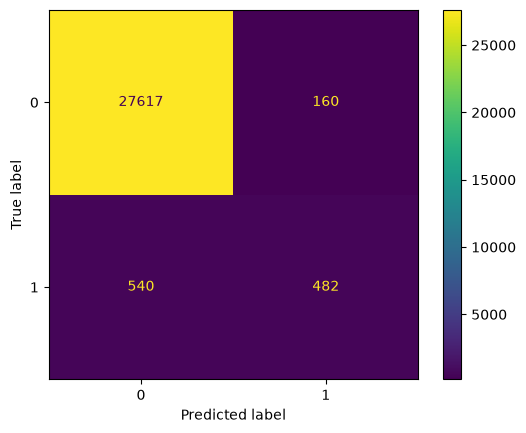

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred);

**The baseline reaches an F1-score of about 0.6. Your turn: beat it! 🚀**

A few ideas:

- use **all** the features: the categorical ones need a `OneHotEncoder`, the numerical ones a `StandardScaler` (see the cell below);
- move the **decision threshold**: `predict` uses 0.5, but with rare conversions another threshold may give a better F1-score (use `predict_proba`);
- try other models (trees, random forests, gradient boosting) and tune them with a grid search.

In [ ]:
# Example: a model that uses every feature (uncomment to try it)
# categorical = ["country", "source"]
# numerical = ["age", "new_user", "total_pages_visited"]
# features = categorical + numerical
# X = data[features]
# X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, stratify=y, random_state=0)
#
# preprocessing = ColumnTransformer([
#     ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
#     ("numerical", StandardScaler(), numerical),
# ])
# model = Pipeline([("preprocessing", preprocessing), ("classifier", LogisticRegression(max_iter=1000))])
# model.fit(X_train, y_train)
# print(f"F1-score on the validation set: {f1_score(y_val, model.predict(X_val)):.4f}")

## Train on all the labelled data and make a submission

Once you have chosen your model, train it again on **all** the labelled data: more examples often bring a small improvement. Then predict `conversion_test.csv`.

In [ ]:
model.fit(data[features], data[target])

test = pd.read_csv("data/conversion_test.csv")
print("Rows to predict:", test.shape)

predictions = pd.DataFrame({"converted": model.predict(test[features])})

team_name = "my-team"   # <- change it!
predictions.to_csv(f"conversion_predictions_{team_name}.csv", index=False)

# check the format before sending the file
assert list(predictions.columns) == ["converted"] and len(predictions) == len(test)
print(f"Saved conversion_predictions_{team_name}.csv with {predictions['converted'].sum()} predicted conversions")

Rows to predict: (32013, 5)
Saved conversion_predictions_my-team.csv with 754 predicted conversions


## Interpret your model

With a single feature there is not much to interpret 🤔 Once your model uses more features, look at its coefficients (or feature importances): which features increase the chances of subscribing? What lever for action would you suggest to the newsletter team? 😎